In [21]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from matplotlib.colors import PowerNorm


def infer_box2_from_box1(box1_coords, pattern_height):
    (y_min, y_max), (x_min, x_max) = box1_coords
    box2_y_min = pattern_height - y_max
    box2_y_max = pattern_height - y_min
    return ((box2_y_min, box2_y_max), (x_min, x_max))


def _parse_box_coords(box_coords, H, W):
    """Convert box coords (fractional or pixel) to integer pixel indices."""
    (y_min, y_max), (x_min, x_max) = box_coords
    if 0 <= y_min <= 1 and 0 <= y_max <= 1:
        y_min, y_max = int(y_min * H), int(y_max * H)
    if 0 <= x_min <= 1 and 0 <= x_max <= 1:
        x_min, x_max = int(x_min * W), int(x_max * W)
    y_min = max(0, min(int(y_min), H - 1))
    y_max = max(0, min(int(y_max), H))
    x_min = max(0, min(int(x_min), W - 1))
    x_max = max(0, min(int(x_max), W))
    return y_min, y_max, x_min, x_max


def _intensity_asymmetry_vectorized(
    patterns, box1_coords, box2_coords, sign_flip=False
):
    """Vectorized intensity asymmetry (sum(box1) - sum(box2)) over all tilt points.

    patterns : ndarray, shape (n_tilt, H, W), float64
    Returns  : ndarray, shape (n_tilt,)
    """
    n_tilt, H, W = patterns.shape
    y1_min, y1_max, x1_min, x1_max = _parse_box_coords(box1_coords, H, W)
    y2_min, y2_max, x2_min, x2_max = _parse_box_coords(box2_coords, H, W)

    b1_sum = patterns[:, y1_min:y1_max, x1_min:x1_max].sum(axis=(1, 2))
    b2_sum = patterns[:, y2_min:y2_max, x2_min:x2_max].sum(axis=(1, 2))
    result = b1_sum - b2_sum
    return -result if sign_flip else result


def load_patterns(path):
    """Load diffraction images from NPZ, returning (n_tilt, H, W) float64."""
    data = np.load(path)
    imgs = data["diffraction_images"].astype(np.float64)
    # Handle both (n_tilt, H, W) and (n_tilt, 1, H, W) layouts
    if imgs.ndim == 4:
        imgs = imgs[:, 0]
    return imgs, data

In [37]:
# ── Colours ──────────────────────────────────────────────────────────────────
C_200_RANGE = "#d31f11"
C_300_RANGE = "#f47a00"
C_200      = "#62c8d3"
C_300      = "#007191"

GAMMA = 0.3
PERCENTILE_MIN = 0.5
PERCENTILE_MAX = 99.8

# ── Per-material configuration ────────────────────────────────────────────────
# Each entry in "boxes" defines one box-pair:
#   box1      : ((y_min, y_max), (x_min, x_max))  — upper box in pixel coords
#   box2 is automatically inferred as the vertical mirror of box1
#   color     : hex colour for both box outlines and the asymmetry line
#   ls        : linestyle for the asymmetry line ("-", "--", etc.)
# transpose   : set True to rotate the pattern 90° (np.transpose) before
#               any display or calculation — use when the simulation was built
#               with axes swapped relative to the other materials.

MATERIALS = {
    "PTO": {
        "label": r"$\mathrm{PbTiO_3}$ (PTO)",
        "path": "/leonardo_work/EUHPC_E06_088/fhardy00/cbed_simulations/PTO_disk_intensity_sweeps/PTO_disk_intensity_job39823535/results.npz",
        "sign_flip": True,
        "tilt_flip": True,
        "transpose": True,   # PTO simulation was set up 90° rotated
        "boxes": [
            {"name": "[200] range",     "box1": ((140, 160), (170, 254)), "color": C_300,       "ls": "-"},
            {"name": "[300] range",    "box1": ((110, 130),  (170, 254)), "color": C_300_RANGE, "ls": "-"},
            {"name": "[200]", "box1": ((140, 160), (200, 224)), "color": C_200,       "ls": "--"},
            {"name": "[300]", "box1": ((110, 130), (200, 223)), "color": C_200_RANGE, "ls": "--"},
        ],
    },
    "BTO": {
        "label": r"$\mathrm{BaTiO_3}$ (BTO)",
        "path": "/leonardo_work/EUHPC_E06_088/fhardy00/cbed_simulations/BTO_disk_intensity_sweeps/BTO_disk_intensity_job39815678/results.npz",
        "sign_flip": True,
        "tilt_flip": True,
        "transpose": False,
        "boxes": [
            {"name": "[200] range",     "box1": ((150, 165), (175, 254)), "color": C_300,       "ls": "-"},
            {"name": "[300] range",    "box1": ((115, 135),  (175, 254)), "color": C_300_RANGE, "ls": "-"},
            {"name": "[200]", "box1": ((150, 165), (200, 228)), "color": C_200,       "ls": "--"},
            {"name": "[300]", "box1": ((115, 135), (200, 228)), "color": C_200_RANGE, "ls": "--"},
        ],
    },
    "Boracite": {
        "label": r"$\mathrm{Cu_3B_7ClO_{13}}$ (Boracite)",
        "path": "/leonardo_work/EUHPC_E06_088/fhardy00/cbed_simulations/boracite_disk_intensity_sweeps/boracite_disk_intensity_job39815687/results.npz",
        "sign_flip": True,
        "tilt_flip": True,
        "transpose": False,
        "boxes": [
            {"name": "[100] range",     "box1": ((267, 283), (266, 340)), "color": C_300,       "ls": "-"},
            {"name": "[200] range",    "box1": ((240, 255),  (266, 340)), "color": C_300_RANGE, "ls": "-"},
            {"name": "[100]", "box1": ((267, 283), (293, 313)), "color": C_200,       "ls": "--"},
            {"name": "[200]", "box1": ((240, 255), (293, 313)), "color": C_200_RANGE, "ls": "--"},
        ],
    },
}

In [38]:
def process_material(name, cfg):
    """Load NPZ and compute intensity asymmetry for each box defined in cfg."""
    patterns, data = load_patterns(cfg["path"])

    # Optionally transpose every pattern (swaps x/y axes) to correct for
    # simulations that were built with the crystal rotated 90° relative to others.
    if cfg.get("transpose", False):
        patterns = np.transpose(patterns, axes=(0, 2, 1))
        print(f"  {name}: patterns transposed → shape {patterns.shape}")

    n_tilt, H, W = patterns.shape

    tilt_y = list(data["tilt_y_values"])
    if cfg.get("tilt_flip", False):
        tilt_y = [-v for v in tilt_y]

    sign = -1 if cfg.get("sign_flip", False) else 1

    box_results = {}
    for bdef in cfg["boxes"]:
        bname  = bdef["name"]
        box1   = bdef["box1"]
        color  = bdef["color"]
        ls     = bdef["ls"]
        box2   = infer_box2_from_box1(box1, H)
        vals   = sign * _intensity_asymmetry_vectorized(patterns, box1, box2)
        box_results[bname] = {
            "vals":  vals,
            "box1":  box1,
            "box2":  box2,
            "color": color,
            "ls":    ls,
        }
        print(f"  {name} [{bname}]: box1={box1}, box2={box2}")

    # Zero-tilt pattern for display (middle of tilt sweep)
    zero_idx = len(tilt_y) // 2
    zero_tilt_image = patterns[zero_idx]

    return {
        "tilt_y":          tilt_y,
        "box_results":     box_results,
        "zero_tilt_image": zero_tilt_image,
        "H": H,
        "W": W,
    }


results = {}
for name, cfg in MATERIALS.items():
    print(f"Processing {name}…")
    results[name] = process_material(name, cfg)
print("Done.")

Processing PTO…
  PTO: patterns transposed → shape (41, 424, 418)
  PTO [[200] range]: box1=((140, 160), (170, 254)), box2=((264, 284), (170, 254))
  PTO [[300] range]: box1=((110, 130), (170, 254)), box2=((294, 314), (170, 254))
  PTO [[200]]: box1=((140, 160), (200, 224)), box2=((264, 284), (200, 224))
  PTO [[300]]: box1=((110, 130), (200, 223)), box2=((294, 314), (200, 223))
Processing BTO…
  BTO [[200] range]: box1=((150, 165), (175, 254)), box2=((267, 282), (175, 254))
  BTO [[300] range]: box1=((115, 135), (175, 254)), box2=((297, 317), (175, 254))
  BTO [[200]]: box1=((150, 165), (200, 228)), box2=((267, 282), (200, 228))
  BTO [[300]]: box1=((115, 135), (200, 228)), box2=((297, 317), (200, 228))
Processing Boracite…
  Boracite [[100] range]: box1=((267, 283), (266, 340)), box2=((323, 339), (266, 340))
  Boracite [[200] range]: box1=((240, 255), (266, 340)), box2=((351, 366), (266, 340))
  Boracite [[100]]: box1=((267, 283), (293, 313)), box2=((323, 339), (293, 313))
  Boracite

Name: PTO, Shape: (424, 418)
Name: BTO, Shape: (432, 428)
Name: Boracite, Shape: (606, 606)


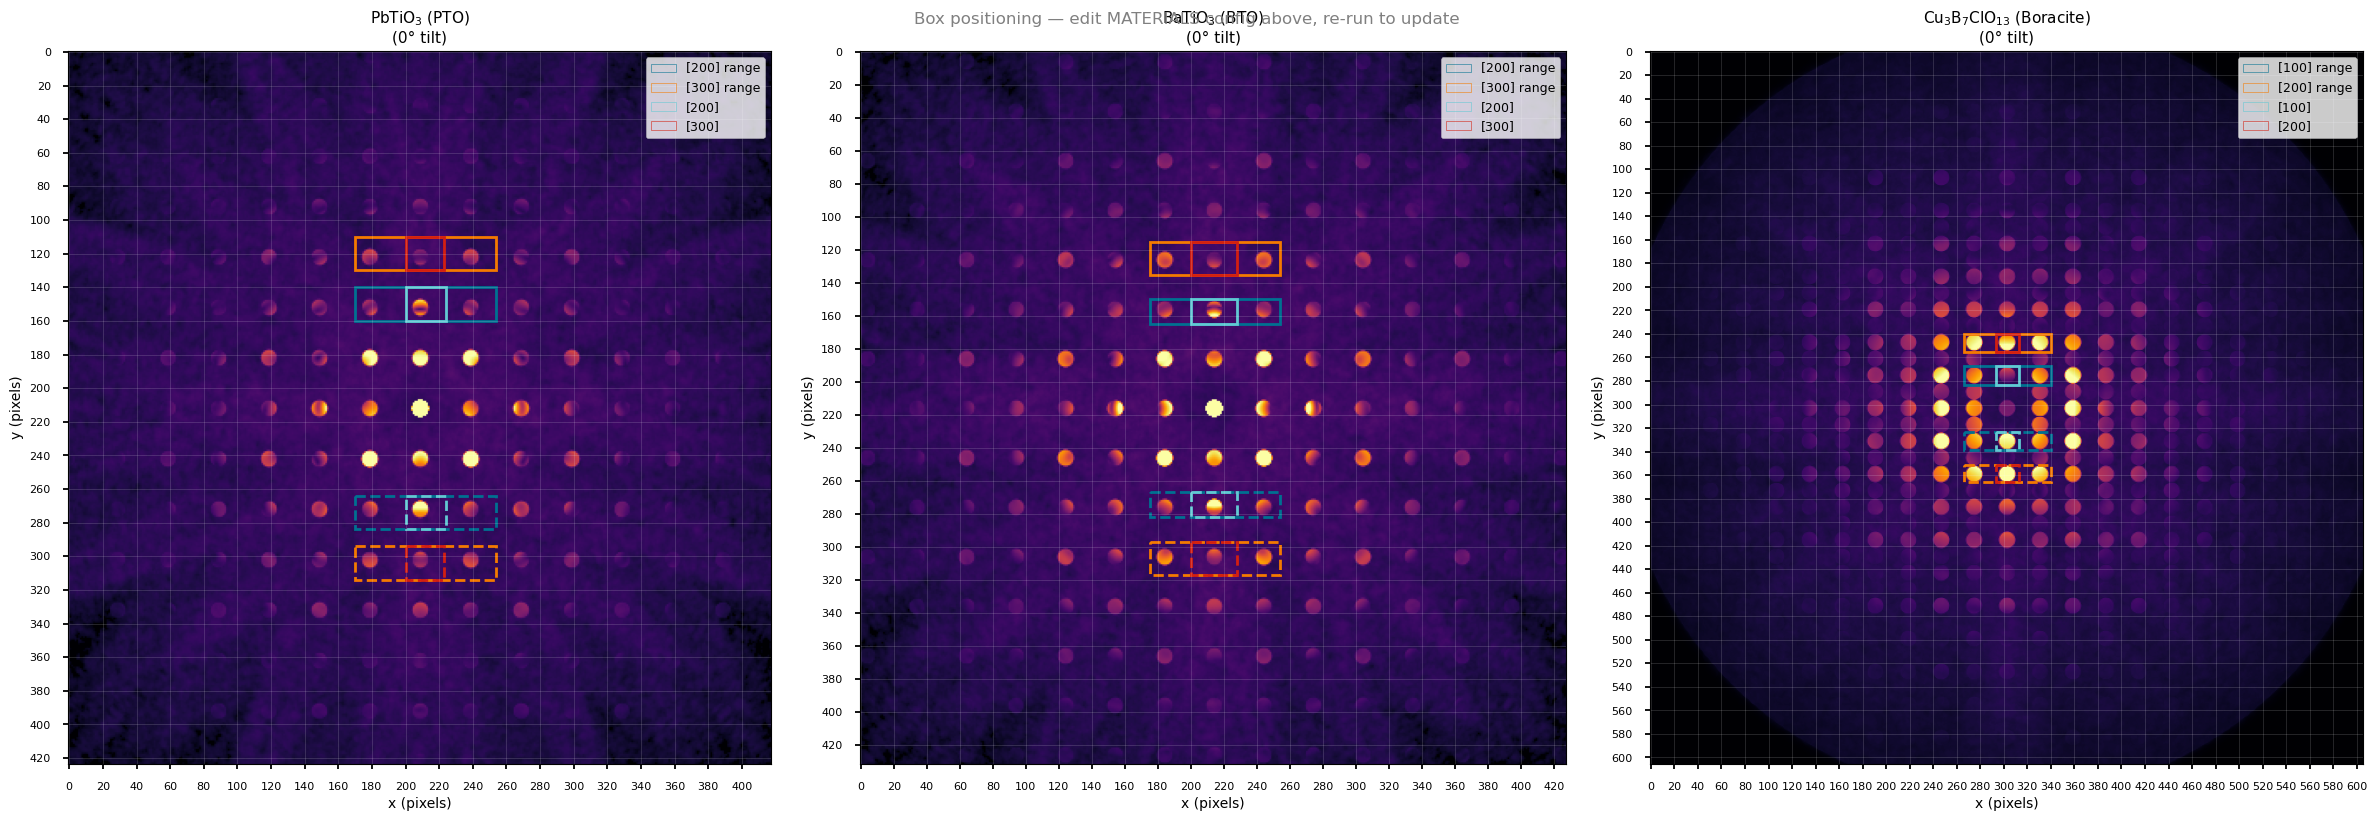

In [39]:
# ── Box positioning helper — 1×3 grid, axes ON so you can read pixel coords ──
# Adjust the box coordinates in MATERIALS["..."]["boxes"] above, then re-run
# this cell to check placement without re-running the full simulation load.

fig, axes = plt.subplots(1, 3, figsize=(24, 8))

for ax, (name, res) in zip(axes, results.items()):
    img = res["zero_tilt_image"]
    vmin = np.percentile(img, PERCENTILE_MIN)
    vmax = np.percentile(img, PERCENTILE_MAX)

    print(f"Name: {name}, Shape: {img.shape}")

    ax.imshow(
        img,
        cmap="inferno",
        origin="upper",
        norm=PowerNorm(gamma=GAMMA, vmin=vmin, vmax=vmax),
    )

    legend_handles, legend_labels = [], []
    for bname, br in res["box_results"].items():
        draw_box(ax, br["box1"], br["color"], linestyle="-",  lw=2)
        draw_box(ax, br["box2"], br["color"], linestyle="--", lw=2)
        legend_handles.append(
            Rectangle((0, 0), 1, 1, edgecolor=br["color"], facecolor="none")
        )
        legend_labels.append(bname)

    ax.legend(legend_handles, legend_labels, fontsize=9, loc="upper right")
    ax.set_title(f"{MATERIALS[name]['label']}\n(0° tilt)", fontsize=11)
    ax.set_xlabel("x (pixels)", fontsize=10)
    ax.set_ylabel("y (pixels)", fontsize=10)
    ax.tick_params(labelsize=8)
    # Grid lines every 200 px to help read off coordinates
    H, W = res["H"], res["W"]
    ax.set_xticks(range(0, W + 1, 20))
    ax.set_yticks(range(0, H + 1, 20))
    ax.grid(True, color="white", alpha=0.2, linewidth=0.5)

plt.suptitle("Box positioning — edit MATERIALS config above, re-run to update",
             fontsize=12, color="gray")
plt.tight_layout()
plt.show()

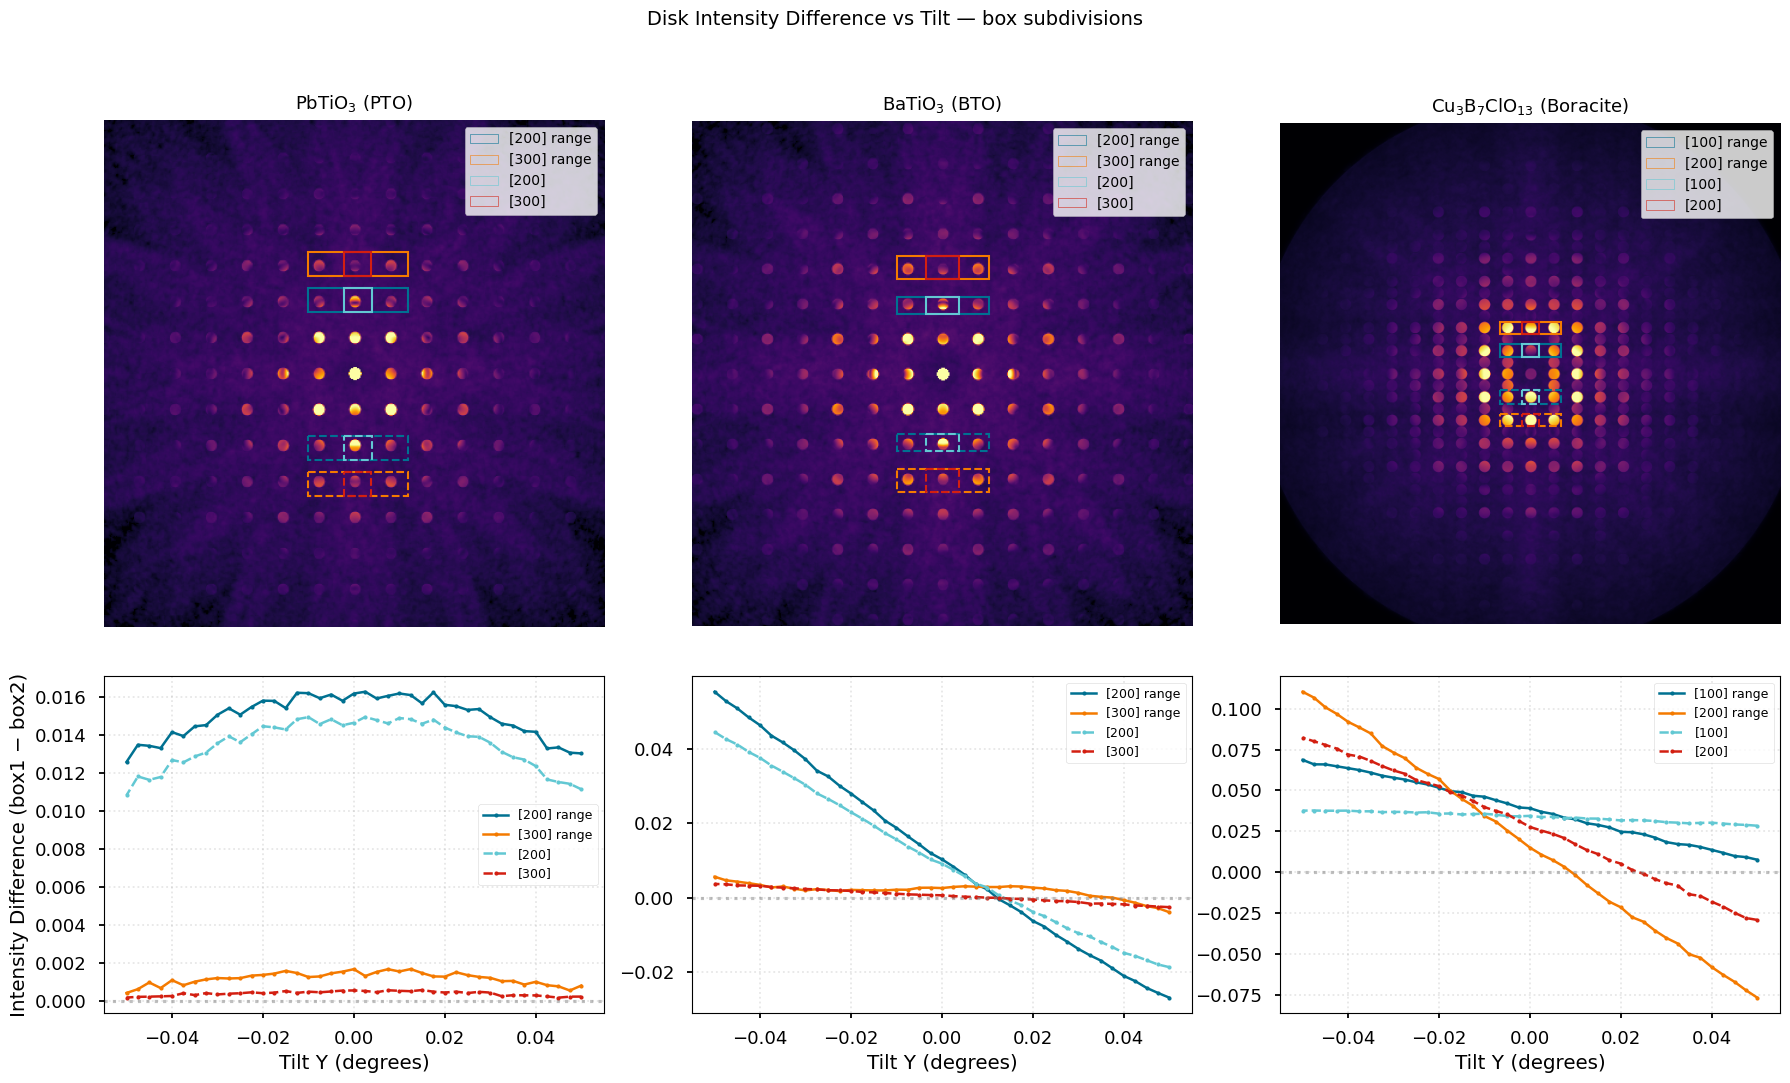

In [40]:
def draw_box(ax, box, color, linestyle="-", lw=1.5):
    (y_lo, y_hi), (x_lo, x_hi) = box
    ax.add_patch(
        Rectangle(
            (x_lo, y_lo),
            x_hi - x_lo,
            y_hi - y_lo,
            linewidth=lw,
            edgecolor=color,
            facecolor="none",
            linestyle=linestyle,
        )
    )


plt.style.use("seaborn-v0_8-talk")
fig, axes = plt.subplots(2, 3, figsize=(18, 11), gridspec_kw={"height_ratios": [2, 1]})

for col, (name, res) in enumerate(results.items()):
    # ── Top row: diffraction pattern at 0° tilt with box overlays ─────────────
    ax_img = axes[0, col]
    img = res["zero_tilt_image"]
    vmin = np.percentile(img, PERCENTILE_MIN)
    vmax = np.percentile(img, PERCENTILE_MAX)
    ax_img.imshow(
        img,
        cmap="inferno",
        origin="upper",
        norm=PowerNorm(gamma=GAMMA, vmin=vmin, vmax=vmax),
    )

    legend_handles = []
    legend_labels = []
    for bname, br in res["box_results"].items():
        draw_box(ax_img, br["box1"], br["color"], linestyle="-")
        draw_box(ax_img, br["box2"], br["color"], linestyle="--")
        legend_handles.append(
            Rectangle(
                (0, 0), 1, 1, edgecolor=br["color"], facecolor="none", linestyle="-"
            )
        )
        legend_labels.append(bname)

    ax_img.legend(legend_handles, legend_labels, fontsize=10, loc="upper right")
    ax_img.set_title(MATERIALS[name]["label"], fontsize=13, pad=8)
    ax_img.axis("off")

    # ── Bottom row: intensity difference vs tilt ───────────────────────────────
    ax = axes[1, col]
    for bname, br in res["box_results"].items():
        ax.plot(
            res["tilt_y"],
            br["vals"],
            marker="o",
            markersize=3,
            linestyle=br["ls"],
            color=br["color"],
            label=bname,
            linewidth=1.8,
        )
    ax.axhline(0, color="gray", linestyle=":", alpha=0.5)
    ax.set_xlabel("Tilt Y (degrees)")
    ax.legend(fontsize=9)
    ax.grid(True, alpha=0.3, linestyle=":")

axes[1, 0].set_ylabel("Intensity Difference (box1 − box2)")
fig.suptitle("Disk Intensity Difference vs Tilt — box subdivisions", fontsize=14)
plt.tight_layout()
plt.show()

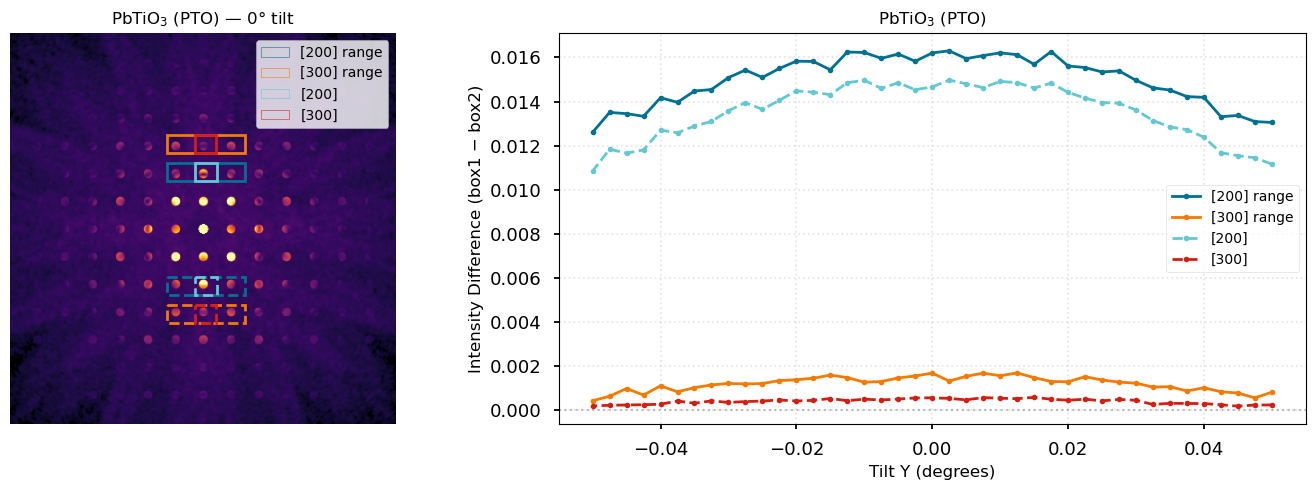

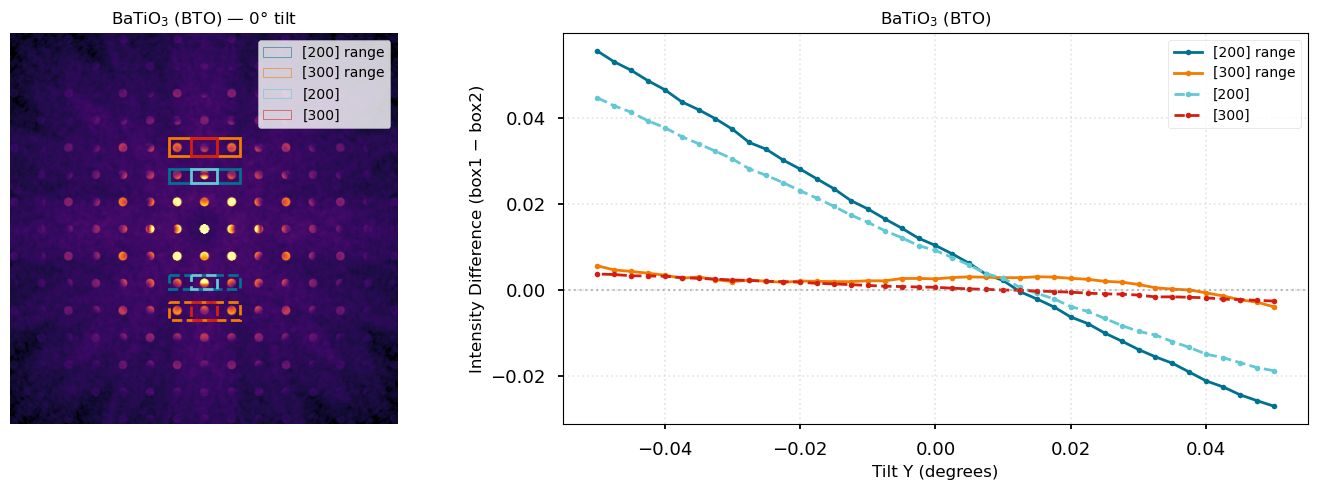

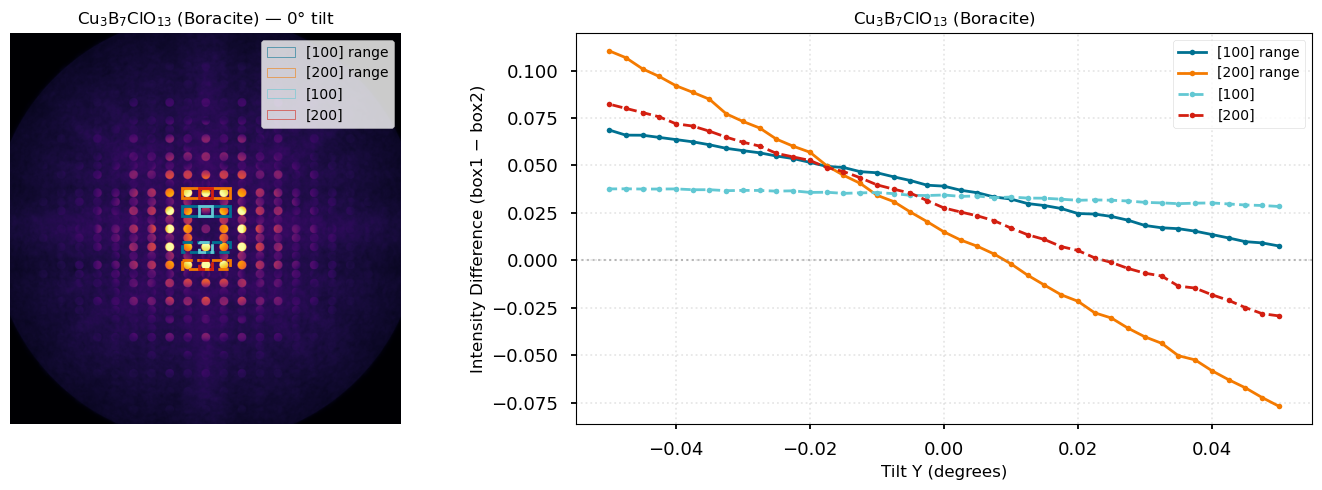

In [41]:
# ── One figure per material — larger, easier to read ─────────────────────────
for name, res in results.items():
    fig2, axes2 = plt.subplots(
        1, 2, figsize=(14, 5), gridspec_kw={"width_ratios": [1, 1.4]}
    )

    # Pattern with boxes
    ax_img = axes2[0]
    img = res["zero_tilt_image"]
    vmin = np.percentile(img, PERCENTILE_MIN)
    vmax = np.percentile(img, PERCENTILE_MAX)
    ax_img.imshow(
        img,
        cmap="inferno",
        origin="upper",
        norm=PowerNorm(gamma=GAMMA, vmin=vmin, vmax=vmax),
    )

    legend_handles = []
    legend_labels = []
    for bname, br in res["box_results"].items():
        draw_box(ax_img, br["box1"], br["color"], linestyle="-", lw=2)
        draw_box(ax_img, br["box2"], br["color"], linestyle="--", lw=2)
        legend_handles.append(
            Rectangle(
                (0, 0), 1, 1, edgecolor=br["color"], facecolor="none", linestyle="-"
            )
        )
        legend_labels.append(bname)

    ax_img.legend(legend_handles, legend_labels, fontsize=10, loc="upper right")
    ax_img.set_title(f"{MATERIALS[name]['label']} — 0° tilt", fontsize=12)
    ax_img.axis("off")

    # Intensity difference plot
    ax = axes2[1]
    for bname, br in res["box_results"].items():
        ax.plot(
            res["tilt_y"],
            br["vals"],
            marker="o",
            markersize=4,
            linestyle=br["ls"],
            color=br["color"],
            label=bname,
            linewidth=2,
        )
    ax.axhline(0, color="gray", linestyle=":", alpha=0.5, linewidth=1.5)
    ax.set_xlabel("Tilt Y (degrees)", fontsize=12)
    ax.set_ylabel("Intensity Difference (box1 − box2)", fontsize=12)
    ax.set_title(MATERIALS[name]["label"], fontsize=12)
    ax.legend(fontsize=10, frameon=True, loc="best")
    ax.grid(True, alpha=0.3, linestyle=":")

    plt.tight_layout()
    plt.show()